#Drug Recommendation System

##Importing Necessary Libraries

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
%matplotlib inline
from sklearn.svm import SVC
from sklearn.datasets import make_classification
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from xgboost import XGBClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [65]:
# from google.colab import drive
# drive.mount('/content/drive')

##Reading the Dataset

##Training Data

In [66]:
df=pd.read_csv('H:\\Other computers\\My MacBook Air\\work project\\2025\\Drug Recommendation\\drug code\\Dataset\\Drug_Recommendation_Data.csv')

In [67]:
df.head()

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


In [68]:
symptoms_df=pd.read_csv('H:\\Other computers\\My MacBook Air\\work project\\2025\\Drug Recommendation\\drug code\\Dataset\\symtoms_df.csv')

In [69]:
symptoms_df.head()

,Unnamed: 0,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4
0,0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches
1,1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN
2,2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN
3,3,Fungal infection,itching,skin_rash,dischromic _patches,NaN
4,4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN


In [70]:
workout_df=pd.read_csv('H:\\Other computers\\My MacBook Air\\work project\\2025\\Drug Recommendation\\drug code\\Dataset\\workout_df.csv')

In [71]:
workout_df.head()

,Unnamed: 0.1,Unnamed: 0,disease,workout
0,0,0,Fungal infection,Avoid sugary foods
1,1,1,Fungal infection,Consume probiotics
2,2,2,Fungal infection,Increase intake of garlic
3,3,3,Fungal infection,Include yogurt in diet
4,4,4,Fungal infection,Limit processed foods


In [72]:
precautions_df=pd.read_csv('H:\\Other computers\\My MacBook Air\\work project\\2025\\Drug Recommendation\\drug code\\Dataset\\precautions_df.csv')

In [73]:
precautions_df.head()

,Unnamed: 0,Disease,Precaution_1,Precaution_2,Precaution_3,Precaution_4
0,0,Drug Reaction,stop irritation,consult nearest hospital,stop taking drug,follow up
1,1,Malaria,Consult nearest hospital,avoid oily food,avoid non veg food,keep mosquitos out
2,2,Allergy,apply calamine,cover area with bandage,NaN,use ice to compress itching
3,3,Hypothyroidism,reduce stress,exercise,eat healthy,get proper sleep
4,4,Psoriasis,wash hands with warm soapy water,stop bleeding using pressure,consult doctor,salt baths


In [74]:
medications_df=pd.read_csv('H:\\Other computers\\My MacBook Air\\work project\\2025\\Drug Recommendation\\drug code\\Dataset\\medications.csv')

In [75]:
medications_df.head()

,Disease,Medication
0,Fungal infection,"['Antifungal Cream', 'Fluconazole', 'Terbinafi..."
1,Allergy,"['Antihistamines', 'Decongestants', 'Epinephri..."
2,GERD,"['Proton Pump Inhibitors (PPIs)', 'H2 Blockers..."
3,Chronic cholestasis,"['Ursodeoxycholic acid', 'Cholestyramine', 'Me..."
4,Drug Reaction,"['Antihistamines', 'Epinephrine', 'Corticoster..."


In [76]:
diets_df=pd.read_csv('H:\\Other computers\\My MacBook Air\\work project\\2025\\Drug Recommendation\\drug code\\Dataset\\diets.csv')

In [77]:
diets_df.head()

,Disease,Diet
0,Fungal infection,"['Antifungal Diet', 'Probiotics', 'Garlic', 'C..."
1,Allergy,"['Elimination Diet', 'Omega-3-rich foods', 'Vi..."
2,GERD,"['Low-Acid Diet', 'Fiber-rich foods', 'Ginger'..."
3,Chronic cholestasis,"['Low-Fat Diet', 'High-Fiber Diet', 'Lean prot..."
4,Drug Reaction,"['Antihistamine Diet', 'Omega-3-rich foods', '..."


In [78]:
description_df = pd.read_csv('H:\\Other computers\\My MacBook Air\\work project\\2025\\Drug Recommendation\\drug code\\Dataset\\description.csv')

In [79]:
description_df

,Disease,Description
0,Fungal infection,Fungal infection is a common skin condition ca...
1,Allergy,Allergy is an immune system reaction to a subs...
2,GERD,GERD (Gastroesophageal Reflux Disease) is a di...
3,Chronic cholestasis,Chronic cholestasis is a condition where bile ...
4,Drug Reaction,Drug Reaction occurs when the body reacts adve...
5,Peptic ulcer disease,Peptic ulcer disease involves sores that devel...
6,AIDS,AIDS (Acquired Immunodeficiency Syndrome) is a...
7,Diabetes,Diabetes is a chronic condition that affects h...
8,Gastroenteritis,Gastroenteritis is an inflammation of the stom...
9,Bronchial Asthma,Bronchial Asthma is a respiratory condition ch...


##Data Size

In [80]:
df.shape

(4920, 133)

In [81]:
print(df.columns)

Index(['itching', 'skin_rash', 'nodal_skin_eruptions', 'continuous_sneezing',
       'shivering', 'chills', 'joint_pain', 'stomach_pain', 'acidity',
       'ulcers_on_tongue',
       ...
       'blackheads', 'scurring', 'skin_peeling', 'silver_like_dusting',
       'small_dents_in_nails', 'inflammatory_nails', 'blister',
       'red_sore_around_nose', 'yellow_crust_ooze', 'prognosis'],
      dtype='object', length=133)


##Checking Data Types

In [82]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Columns: 133 entries, itching to prognosis
dtypes: int64(132), object(1)
memory usage: 5.0+ MB


##Checking for Duplicate values

In [83]:
print(df.duplicated().sum())

4616


In [84]:
#df=df.drop_duplicates()

##Checking for Null Values

In [85]:
print(df.isnull().sum())

itching                 0
skin_rash               0
nodal_skin_eruptions    0
continuous_sneezing     0
shivering               0
                       ..
inflammatory_nails      0
blister                 0
red_sore_around_nose    0
yellow_crust_ooze       0
prognosis               0
Length: 133, dtype: int64


##Checking unique values in each column

In [86]:
df.nunique()

itching                  2
skin_rash                2
nodal_skin_eruptions     2
continuous_sneezing      2
shivering                2
                        ..
inflammatory_nails       2
blister                  2
red_sore_around_nose     2
yellow_crust_ooze        2
prognosis               41
Length: 133, dtype: int64

In [87]:
for col in df.columns:
    print(df[col].value_counts())
    print('--------')

itching
0    4242
1     678
Name: count, dtype: int64
--------
skin_rash
0    4134
1     786
Name: count, dtype: int64
--------
nodal_skin_eruptions
0    4812
1     108
Name: count, dtype: int64
--------
continuous_sneezing
0    4698
1     222
Name: count, dtype: int64
--------
shivering
0    4812
1     108
Name: count, dtype: int64
--------
chills
0    4122
1     798
Name: count, dtype: int64
--------
joint_pain
0    4236
1     684
Name: count, dtype: int64
--------
stomach_pain
0    4698
1     222
Name: count, dtype: int64
--------
acidity
0    4698
1     222
Name: count, dtype: int64
--------
ulcers_on_tongue
0    4812
1     108
Name: count, dtype: int64
--------
muscle_wasting
0    4812
1     108
Name: count, dtype: int64
--------
vomiting
0    3006
1    1914
Name: count, dtype: int64
--------
burning_micturition
0    4704
1     216
Name: count, dtype: int64
--------
spotting_ urination
0    4812
1     108
Name: count, dtype: int64
--------
fatigue
0    2988
1    1932
Name: count, 

C:\Users\gokul\AppData\Local\Temp\ipykernel_16884\2472366416.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='prognosis', palette='viridis')


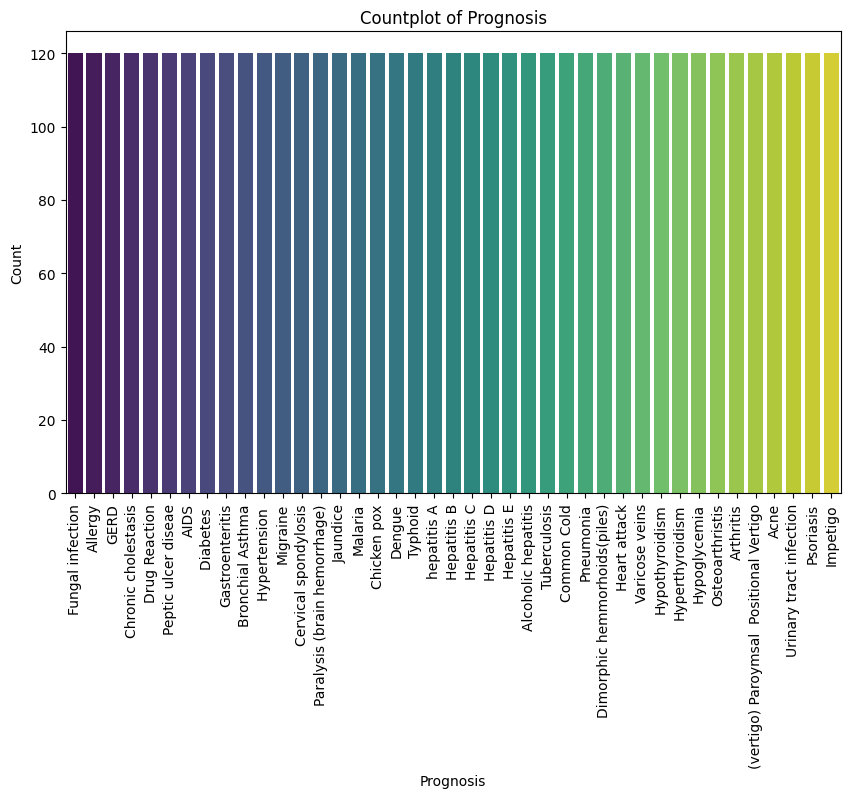

In [88]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x='prognosis', palette='viridis')

plt.title('Countplot of Prognosis')
plt.xlabel('Prognosis')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()

In [89]:
train_df=df.copy()

In [90]:
X = train_df.drop('prognosis', axis=1)
y = train_df['prognosis']

In [91]:
X

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,pus_filled_pimples,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4915,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4916,0,1,0,0,0,0,0,0,0,0,...,1,1,1,0,0,0,0,0,0,0
4917,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4918,0,1,0,0,0,0,1,0,0,0,...,0,0,0,1,1,1,1,0,0,0


In [92]:
le=LabelEncoder()

In [93]:
le.fit(y)
Y = le.transform(y)

In [94]:
Y

array([15, 15, 15, ..., 38, 35, 27])

In [95]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [96]:
X_train.shape , y_train.shape

((3936, 132), (3936,))

In [97]:
X_test.shape , y_test.shape

((984, 132), (984,))

#SVC

In [98]:
svc = SVC()
svc.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [99]:
print(" SVC Accuracy on training set: {:.3f}".format(svc.score(X_train, y_train)))

 SVC Accuracy on training set: 1.000


# RandomForest

In [100]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [101]:
print("RandomForest Accuracy on training set: {:.3f}".format(rf.score(X_train, y_train)))

RandomForest Accuracy on training set: 1.000


# GradientBoosting

In [102]:
gboot = GradientBoostingClassifier()
gboot.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [103]:
print("GradientBoosting Accuracy on training set: {:.3f}".format(rf.score(X_train, y_train)))

GradientBoosting Accuracy on training set: 1.000


# Pickle file

In [104]:
#save gboot
pickle.dump(gboot,open('drug_gboot.pkl','wb'))

In [105]:
# load model
gboot = pickle.load(open('drug_gboot.pkl','rb'))

In [106]:
# test 1:
print("predicted disease :",gboot.predict(X_test.iloc[45].values.reshape(1,-1)))
print("Actual Disease :", y_test[45])

predicted disease : [17]
Actual Disease : 17


c:\Users\gokul\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


In [107]:
# test 2:
print("predicted disease :",gboot.predict(X_test.iloc[350].values.reshape(1,-1)))
print("Actual Disease :", y_test[350])

predicted disease : [11]
Actual Disease : 11


c:\Users\gokul\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


# Drug Recommendation

In [ ]:
def helper(dis):
    desc = description_df[description_df['Disease'] == predicted_disease]['Description']
    desc = " ".join([w for w in desc])

    pre = precautions_df[precautions_df['Disease'] == dis][['Precaution_1', 'Precaution_2', 'Precaution_3', 'Precaution_4']]
    pre = [col for col in pre.values]

    med = medications_df[medications_df['Disease'] == dis]['Medication']
    med = [med for med in med.values]

    die = diets_df[diets_df['Disease'] == dis]['Diet']
    die = [die for die in die.values]

    wrkout = workout_df[workout_df['disease'] == dis] ['workout']


    return desc,pre,med,die,wrkout

# List of symptoms (kept as the same tokens used elsewhere)
symptom_list = [
    'itching','skin_rash','nodal_skin_eruptions','continuous_sneezing','shivering','chills','joint_pain',
    'stomach_pain','acidity','ulcers_on_tongue','muscle_wasting','vomiting','burning_micturition',
    'spotting_ urination','fatigue','weight_gain','anxiety','cold_hands_and_feets','mood_swings','weight_loss',
    'restlessness','lethargy','patches_in_throat','irregular_sugar_level','cough','high_fever','sunken_eyes',
    'breathlessness','sweating','dehydration','indigestion','headache','yellowish_skin','dark_urine','nausea',
    'loss_of_appetite','pain_behind_the_eyes','back_pain','constipation','abdominal_pain','diarrhoea','mild_fever',
    'yellow_urine','yellowing_of_eyes','acute_liver_failure','fluid_overload','swelling_of_stomach','swelled_lymph_nodes',
    'malaise','blurred_and_distorted_vision','phlegm','throat_irritation','redness_of_eyes','sinus_pressure','runny_nose',
    'congestion','chest_pain','weakness_in_limbs','fast_heart_rate','pain_during_bowel_movements','pain_in_anal_region',
    'bloody_stool','irritation_in_anus','neck_pain','dizziness','cramps','bruising','obesity','swollen_legs',
    'swollen_blood_vessels','puffy_face_and_eyes','enlarged_thyroid','brittle_nails','swollen_extremeties','excessive_hunger',
    'extra_marital_contacts','drying_and_tingling_lips','slurred_speech','knee_pain','hip_joint_pain','muscle_weakness',
    'stiff_neck','swelling_joints','movement_stiffness','spinning_movements','loss_of_balance','unsteadiness',
    'weakness_of_one_body_side','loss_of_smell','bladder_discomfort','foul_smell_of urine','continuous_feel_of_urine',
    'passage_of_gases','internal_itching','toxic_look_(typhos)','depression','irritability','muscle_pain',
    'altered_sensorium','red_spots_over_body','belly_pain','abnormal_menstruation','dischromic _patches','watering_from_eyes',
    'increased_appetite','polyuria','family_history','mucoid_sputum','rusty_sputum','lack_of_concentration','visual_disturbances',
    'receiving_blood_transfusion','receiving_unsterile_injections','coma','stomach_bleeding','distention_of_abdomen',
    'history_of_alcohol_consumption','fluid_overload.1','blood_in_sputum','prominent_veins_on_calf','palpitations','painful_walking',
    'pus_filled_pimples','blackheads','scurring','skin_peeling','silver_like_dusting','small_dents_in_nails','inflammatory_nails',
    'blister','red_sore_around_nose','yellow_crust_ooze'
]

# Create a LabelEncoder for symptoms and build a mapping symptom -> encoded integer
from sklearn.preprocessing import LabelEncoder
le_sym = LabelEncoder()
le_sym.fit(symptom_list)
encoded = le_sym.transform(symptom_list)
# mapping uses the LabelEncoder encoding (0..n-1)
symptoms_dict = {symptom: int(idx) for symptom, idx in zip(symptom_list, encoded)}

# Build diseases mapping using the LabelEncoder `le` fitted earlier (fallback to manual mapping)
manual_diseases_list = {15: 'Fungal infection', 4: 'Allergy', 16: 'GERD', 9: 'Chronic cholestasis', 14: 'Drug Reaction', 33: 'Peptic ulcer diseae', 1: 'AIDS', 12: 'Diabetes ', 17: 'Gastroenteritis', 6: 'Bronchial Asthma', 23: 'Hypertension ', 30: 'Migraine', 7: 'Cervical spondylosis', 32: 'Paralysis (brain hemorrhage)', 28: 'Jaundice', 29: 'Malaria', 8: 'Chicken pox', 11: 'Dengue', 37: 'Typhoid', 40: 'hepatitis A', 19: 'Hepatitis B', 20: 'Hepatitis C', 21: 'Hepatitis D', 22: 'Hepatitis E', 3: 'Alcoholic hepatitis', 36: 'Tuberculosis', 10: 'Common Cold', 34: 'Pneumonia', 13: 'Dimorphic hemmorhoids(piles)', 18: 'Heart attack', 39: 'Varicose veins', 26: 'Hypothyroidism', 24: 'Hyperthyroidism', 25: 'Hypoglycemia', 31: 'Osteoarthristis', 5: 'Arthritis', 0: '(vertigo) Paroymsal  Positional Vertigo', 2: 'Acne', 38: 'Urinary tract infection', 35: 'Psoriasis', 27: 'Impetigo'}

if 'le' in globals():
    diseases_list = {int(i): str(cls) for i, cls in enumerate(le.classes_)}
else:
    diseases_list = manual_diseases_list

# Model Prediction function
def get_predicted_value(patient_symptoms):
    input_vector = np.zeros(len(symptoms_dict))
    for item in patient_symptoms:
        if item in symptoms_dict:
            input_vector[symptoms_dict[item]] = 1
    return diseases_list[gboot.predict([input_vector])[0]]

In [109]:
print(symptoms_dict)

{'itching': 56, 'skin_rash': 101, 'nodal_skin_eruptions': 74, 'continuous_sneezing': 25, 'shivering': 97, 'chills': 19, 'joint_pain': 57, 'stomach_pain': 108, 'acidity': 2, 'ulcers_on_tongue': 119, 'muscle_wasting': 70, 'vomiting': 122, 'burning_micturition': 17, 'spotting_ urination': 105, 'fatigue': 41, 'weight_gain': 126, 'anxiety': 5, 'cold_hands_and_feets': 20, 'mood_swings': 66, 'weight_loss': 127, 'restlessness': 93, 'lethargy': 60, 'patches_in_throat': 82, 'irregular_sugar_level': 53, 'cough': 26, 'high_fever': 46, 'sunken_eyes': 109, 'breathlessness': 14, 'sweating': 110, 'dehydration': 29, 'indigestion': 50, 'headache': 45, 'yellowish_skin': 131, 'dark_urine': 28, 'nausea': 72, 'loss_of_appetite': 61, 'pain_behind_the_eyes': 76, 'back_pain': 6, 'constipation': 23, 'abdominal_pain': 0, 'diarrhoea': 31, 'mild_fever': 65, 'yellow_urine': 129, 'yellowing_of_eyes': 130, 'acute_liver_failure': 3, 'fluid_overload': 42, 'swelling_of_stomach': 113, 'swelled_lymph_nodes': 111, 'malaise

In [110]:
# Test 1
# Split the user's input into a list of symptoms (assuming they are comma-separated) # itching,skin_rash,nodal_skin_eruptions
symptoms = input("Enter your symptoms.......")
user_symptoms = [s.strip() for s in symptoms.split(',')]
# Remove any extra characters, if any
user_symptoms = [symptom.strip("[]' ") for symptom in user_symptoms]
predicted_disease = get_predicted_value(user_symptoms)

desc, pre, med, die, wrkout = helper(predicted_disease)

print("=================predicted disease============")
print(predicted_disease)
print("=================description==================")
print(desc)
print("=================precautions==================")
i = 1
for p_i in pre[0]:
    print(i, ": ", p_i)
    i += 1

print("=================medications==================")
for m_i in med:
    print(i, ": ", m_i)
    i += 1

print("=================workout==================")
for w_i in wrkout:
    print(i, ": ", w_i)
    i += 1

print("=================diets==================")
for d_i in die:
    print(i, ": ", d_i)
    i += 1


=================predicted disease============
Chronic cholestasis
=================description==================
Chronic cholestasis is a condition where bile flow from the liver is reduced for a prolonged period.
=================precautions==================
1 :  cold baths
2 :  anti itch medicine
3 :  consult doctor
4 :  eat healthy
=================medications==================
5 :  ['Ursodeoxycholic acid', 'Cholestyramine', 'Methotrexate', 'Corticosteroids', 'Liver transplant']
=================workout==================
6 :  Consume a low-fat diet
7 :  Eat high-fiber foods
8 :  Include healthy fats
9 :  Limit alcohol consumption
10 :  Stay hydrated
11 :  Consume antioxidant-rich foods
12 :  Include omega-3 fatty acids
13 :  Include lean proteins
14 :  Limit processed foods
15 :  Avoid fried foods
=================diets==================
16 :  ['Low-Fat Diet', 'High-Fiber Diet', 'Lean proteins', 'Whole grains', 'Fresh fruits and vegetables']


c:\Users\gokul\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
